# Gatekeeper · 03 — Models 2 and 3: bagging and random forest

A single tree is unstable: small changes in the data give a very different tree.
**Bagging** trains many trees on random resamples of the data and averages their votes.
**Random forest** does the same, but each split may only look at a random handful of columns,
so the trees disagree more and their average is stronger.

Same features, same splits and same scoring as the decision tree, so results are directly comparable.

**Input:** the `train` / `valid` parquet files produced by `01_explore_and_split`.

## 1. Setup — the same in every contest notebook

In [1]:
import os, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

SEARCH_ROOT = os.environ.get("GK_DATA_ROOT", "/kaggle/input")
OUT_DIR = os.environ.get("GK_OUT_DIR", "/kaggle/working")
os.makedirs(OUT_DIR, exist_ok=True)

def find(name):
    hits = glob.glob(f"{SEARCH_ROOT}/**/{name}", recursive=True)
    if not hits:
        raise FileNotFoundError(f"{name} not found: attach the output of 01_explore_and_split as input")
    return hits[0]

train = pd.read_parquet(find("train.parquet"))
valid = pd.read_parquet(find("valid.parquet"))
print(f"train {len(train):,} rows · valid {len(valid):,} rows")

train 414,542 rows · valid 90,568 rows


### Features

- **Not features:** IDs and time counters only record order (`TransactionID`, `TransactionDT`, `day`, `week`).
- **Text columns** (card type, email domain, device…) become numbers: each value gets a code learned from `train`;
  values never seen in training get `-2`.
- **Missing values** become `-999`. Trees simply learn "missing" as its own branch.
  Every model gets this same input, so the comparison is fair.

In [2]:
TARGET = "isFraud"
NOT_FEATURES = {TARGET, "TransactionID", "TransactionDT", "day", "week"}
features = [c for c in train.columns if c not in NOT_FEATURES]
text_cols = [c for c in features if not pd.api.types.is_numeric_dtype(train[c])]

codes = {c: {v: i for i, v in enumerate(train[c].dropna().unique())} for c in text_cols}

def prepare(df):
    X = df[features].copy()
    for c in text_cols:
        X[c] = X[c].map(codes[c]).astype("float32").where(df[c].notna(), -1).fillna(-2)
    return X.fillna(-999).astype("float32")

X_train, y_train = prepare(train), train[TARGET].values
X_valid, y_valid = prepare(valid), valid[TARGET].values
amount_valid = valid["TransactionAmt"].values
print(f"{len(features)} features ({len(text_cols)} were text)")

431 features (31 were text)


### How every model is scored

| Score | Plain meaning |
|---|---|
| **PR-AUC** | Main score. How well the model ranks fraud above genuine payments. Fraud is rare, so this is far more honest than accuracy. A random guess scores about 0.035 here. |
| **Recall @ 1% false alarms** | If we only allow 1 in 100 genuine customers to be wrongly flagged, what share of fraud do we catch? |
| **Cost** | Money lost: every missed fraud costs its amount, and every genuine customer we block costs **$10** (support, lost sales, annoyance). That $10 is our assumption, written down so it can be changed. |
| **Train time / time per payment** | How long it takes to learn, and how long it takes to judge one payment (matters for the 50 ms target). |

In [3]:
FALSE_ALARM_COST = 10.0   # assumed cost of wrongly blocking one genuine customer ($)

def score(name, model, X, y, amount, train_seconds, notes=""):
    t0 = time.perf_counter()
    p = model.predict_proba(X)[:, 1]
    batch_ms = (time.perf_counter() - t0) / len(X) * 1000

    one = X.iloc[[0]]
    t0 = time.perf_counter()
    for _ in range(50):
        model.predict_proba(one)
    single_ms = (time.perf_counter() - t0) / 50 * 1000

    fpr, tpr, thr = roc_curve(y, p)
    i = np.searchsorted(fpr, 0.01, side="right") - 1
    threshold = thr[max(i, 0)]
    flagged = p >= threshold
    missed_fraud = amount[(y == 1) & ~flagged].sum()
    false_alarms = int(((y == 0) & flagged).sum())

    r = {
        "model": name,
        "pr_auc": round(average_precision_score(y, p), 4),
        "roc_auc": round(roc_auc_score(y, p), 4),
        "recall_at_1pct_fpr": round(tpr[max(i, 0)], 4),
        "cost_usd": round(missed_fraud + false_alarms * FALSE_ALARM_COST),
        "missed_fraud_usd": round(missed_fraud),
        "false_alarms": false_alarms,
        "train_seconds": round(train_seconds, 1),
        "ms_per_payment_single": round(single_ms, 3),
        "ms_per_payment_batch": round(batch_ms, 5),
        "notes": notes,
    }
    return r

def show(results):
    cols = ["model", "pr_auc", "recall_at_1pct_fpr", "cost_usd", "train_seconds", "ms_per_payment_single", "notes"]
    return pd.DataFrame(results)[cols]

# Baseline: a model that never flags anything
never = int(y_valid.sum())
print(f"'Never flag' baseline: catches 0 of {never:,} frauds, cost = ${amount_valid[y_valid == 1].sum():,.0f} (all fraud missed)")

'Never flag' baseline: catches 0 of 3,069 frauds, cost = $492,574 (all fraud missed)


In [4]:
# Timing one payment fairly: ensembles can use all CPU cores, but a live API judges one
# payment at a time on one core, so single-payment timing is measured with n_jobs=1.
_score_base = score
def score(name, model, X, y, amount, train_seconds, notes=""):
    jobs = getattr(model, "n_jobs", None)
    if jobs is not None:
        model.set_params(n_jobs=1)
    try:
        return _score_base(name, model, X, y, amount, train_seconds, notes)
    finally:
        if jobs is not None:
            model.set_params(n_jobs=jobs)

# The decision tree's result, for comparison
TREE = {"model": "Decision tree (pruned)", "pr_auc": 0.3678, "recall_at_1pct_fpr": 0.3095,
        "cost_usd": 420500, "train_seconds": 29.7, "ms_per_payment_single": 3.61,
        "notes": "from 02_decision_tree"}
results = []
CPUS = os.cpu_count()
print(f"CPU cores available: {CPUS}")

CPU cores available: 4


## 1. Bagging

- **50 trees**, each grown deep (high variance on its own, which averaging cancels out).
- Each tree sees a random **25% sample** of the training rows, drawn with replacement.
- **Out-of-bag (OOB) score:** every row is left out of most trees' samples, so those trees
  can be tested on it. This gives a free validation score without touching `valid`.

In [5]:
from sklearn.ensemble import BaggingClassifier
from sklearn.tree import DecisionTreeClassifier

t0 = time.perf_counter()
bag = BaggingClassifier(
    estimator=DecisionTreeClassifier(min_samples_leaf=5, random_state=42),
    n_estimators=50, max_samples=0.25, bootstrap=True,
    oob_score=True, n_jobs=-1, random_state=42,
).fit(X_train, y_train)
bag_secs = time.perf_counter() - t0
print(f"Trained 50 trees in {bag_secs:.0f}s")

oob = bag.oob_decision_function_[:, 1]
has_oob = ~np.isnan(oob)
oob_pr = average_precision_score(y_train[has_oob], oob[has_oob])
valid_pr = average_precision_score(y_valid, bag.predict_proba(X_valid)[:, 1])
print(f"OOB PR-AUC   (same months as training): {oob_pr:.3f}  on {has_oob.mean():.0%} of rows")
print(f"Valid PR-AUC (later months):            {valid_pr:.3f}")

Trained 50 trees in 404s
OOB PR-AUC   (same months as training): 0.675  on 100% of rows
Valid PR-AUC (later months):            0.504


**Reading the two scores:** OOB rows come from the same months as the training data, while
`valid` comes from later months. If OOB is clearly higher, part of the gap is fraud patterns
changing over time, which a random split would have hidden.

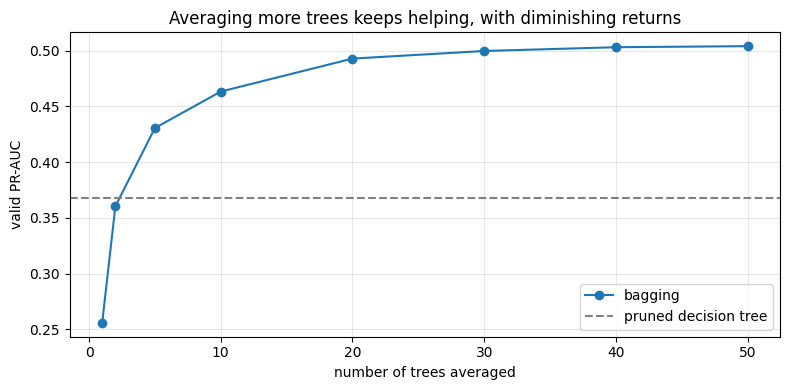

 1 trees: 0.256
 2 trees: 0.360
 5 trees: 0.431
10 trees: 0.463
20 trees: 0.493
30 trees: 0.500
40 trees: 0.503
50 trees: 0.504


In [6]:
# How much does each extra tree help? Average the first k trees' votes on valid.
per_tree = np.column_stack([
    est.predict_proba(X_valid.values[:, feats])[:, 1]
    for est, feats in zip(bag.estimators_, bag.estimators_features_)
])
ks = [1, 2, 5, 10, 20, 30, 40, 50]
curve = [average_precision_score(y_valid, per_tree[:, :k].mean(axis=1)) for k in ks]

plt.figure(figsize=(8, 4))
plt.plot(ks, curve, marker="o", label="bagging")
plt.axhline(TREE["pr_auc"], color="gray", ls="--", label="pruned decision tree")
plt.xlabel("number of trees averaged"); plt.ylabel("valid PR-AUC")
plt.title("Averaging more trees keeps helping, with diminishing returns")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
for k, v in zip(ks, curve):
    print(f"{k:>2} trees: {v:.3f}")

results.append(score("Bagging (50 trees)", bag, X_valid, y_valid, amount_valid, bag_secs,
                     f"25% samples, min_samples_leaf 5, OOB PR-AUC {oob_pr:.3f}"))

## 2. Random forest

Bagging plus one change: at every split, a tree may only consider a random subset of columns
(`max_features`). Trees become less alike, so averaging them cancels more of their errors.
It is also much faster, because each split checks far fewer columns.

First, a quick scan of `max_features` with 100 trees; then the best setting with 300 trees.

In [7]:
from sklearn.ensemble import RandomForestClassifier

n_feat = X_train.shape[1]
options = {"sqrt": "sqrt", "5%": 0.05, "15%": 0.15}
scan = []
for label, mf in options.items():
    t0 = time.perf_counter()
    rf = RandomForestClassifier(n_estimators=100, max_features=mf, min_samples_leaf=5,
                                max_samples=0.25, n_jobs=-1, random_state=42).fit(X_train, y_train)
    s = time.perf_counter() - t0
    v = average_precision_score(y_valid, rf.predict_proba(X_valid)[:, 1])
    k = int(np.sqrt(n_feat)) if mf == "sqrt" else int(mf * n_feat)
    scan.append({"max_features": label, "columns_per_split": k, "valid_pr_auc": round(v, 4), "seconds": round(s)})
    print(f"max_features {label:>4} (~{k} columns per split): valid PR-AUC {v:.3f}  ({s:.0f}s)")

scan = pd.DataFrame(scan)
best_label = scan.loc[scan["valid_pr_auc"].idxmax(), "max_features"]
print(f"\nBest: {best_label}")

max_features sqrt (~20 columns per split): valid PR-AUC 0.485  (28s)
max_features   5% (~21 columns per split): valid PR-AUC 0.484  (29s)
max_features  15% (~64 columns per split): valid PR-AUC 0.502  (90s)

Best: 15%


In [8]:
t0 = time.perf_counter()
forest = RandomForestClassifier(n_estimators=300, max_features=options[best_label], min_samples_leaf=5,
                                max_samples=0.25, n_jobs=-1, random_state=42).fit(X_train, y_train)
forest_secs = time.perf_counter() - t0
print(f"300 trees trained in {forest_secs:.0f}s")

results.append(score("Random forest (300 trees)", forest, X_valid, y_valid, amount_valid, forest_secs,
                     f"max_features {best_label}, 25% samples, min_samples_leaf 5"))
show([TREE] + results)

300 trees trained in 267s


,model,pr_auc,recall_at_1pct_fpr,cost_usd,train_seconds,ms_per_payment_single,notes
0,Decision tree (pruned),0.3678,0.3095,420500,29.7,3.610,from 02_decision_tree
1,Bagging (50 trees),0.5040,0.4262,321614,404.4,7.843,"25% samples, min_samples_leaf 5, OOB PR-AUC 0.675"
2,Random forest (300 trees),0.5043,0.4164,322172,267.1,16.978,"max_features 15%, 25% samples, min_samples_leaf 5"


## 3. What the forest relies on

Importance spread over 300 trees is more stable than a single tree's. Comparing the two lists
shows whether the tree's top columns were real signals or luck.

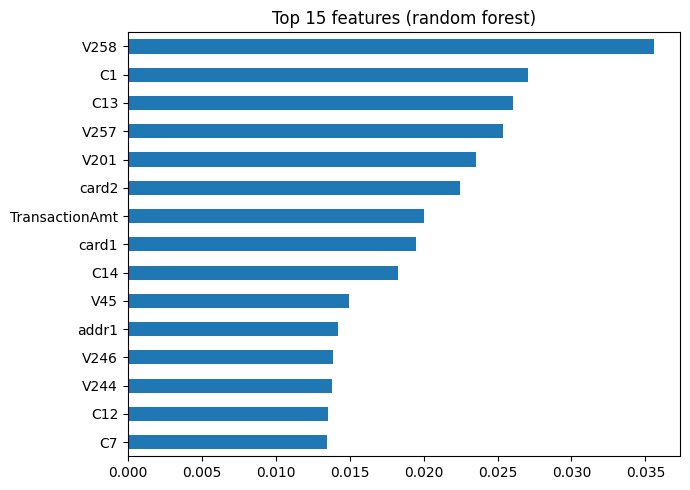

Top 6: V258, C1, C13, V257, V201, card2


In [9]:
imp = pd.Series(forest.feature_importances_, index=features).sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(7, 5))
imp[::-1].plot.barh(ax=ax, title="Top 15 features (random forest)")
plt.tight_layout(); plt.show()
print("Top 6:", ", ".join(imp.index[:6]))

## 4. Save the results

In [10]:
path = f"{OUT_DIR}/results_bagging_rf.json"
with open(path, "w") as f:
    json.dump(results, f, indent=2)
print("saved", path)
show([TREE] + results)

saved /kaggle/working/results_bagging_rf.json


,model,pr_auc,recall_at_1pct_fpr,cost_usd,train_seconds,ms_per_payment_single,notes
0,Decision tree (pruned),0.3678,0.3095,420500,29.7,3.610,from 02_decision_tree
1,Bagging (50 trees),0.5040,0.4262,321614,404.4,7.843,"25% samples, min_samples_leaf 5, OOB PR-AUC 0.675"
2,Random forest (300 trees),0.5043,0.4164,322172,267.1,16.978,"max_features 15%, 25% samples, min_samples_leaf 5"
